**Neural networks for road segmentation**
========================

Your next task is to train neural network to segment road on images from car cams.

The original dataset is provided by Karlsruhe Institute of Technology (http://www.cvlibs.net/datasets/kitti/eval_road.php). Their images are ±370x1270, but, for simlictiy, we will use 370x370 squares.

One can download the dataset from https://disk.yandex.ru/d/QPOw4hk84-se_w

Here is an example of input data with corresponding ground truth:

In [1]:
import os
import cv2
import numpy as np
from tqdm import tqdm

import torch
from torch import nn
from torch.functional import F
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader

import albumentations

import matplotlib.pyplot as plt
from matplotlib.axes import Axes
%matplotlib inline

In [2]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f"{device=}")

device=device(type='cuda', index=0)


In [3]:
def get_paths(path):
    _, _, filenames = next(os.walk(path))

    images_paths = []
    for filename in sorted(filenames):            
        images_paths.append(os.path.join(path, filename))
    
    return np.stack(images_paths)

class RoadDataset(Dataset):
    """Feel free to rewrite it. For ex. cache all images in RAM to increase training speed"""
    def __init__(self, images, masks, transform, aug=None):
        self.images = [cv2.imread(im_name)[:,:,::-1].copy() for im_name in sorted(images)] # ::-1 to convert from BGR to RGB
        self.masks = [(cv2.imread(mask_name, cv2.IMREAD_GRAYSCALE) > 0).astype(np.int8) for mask_name in sorted(masks)]
        self.transform = transform
        self.aug = aug
    
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):        
        image = self.images[idx]
        mask = self.masks[idx]
        
        if self.aug:
            sample = self.aug(
                image=image,
                mask=mask,
            )
        else:
            sample = {
                'image': image,
                'mask': mask,
            }
        
        sample['image'] = self.transform(sample['image']).float()
        sample['mask'] = self.transform(sample['mask']).float()

        return sample

In [4]:
X_train = get_paths("/data/bojkoar/deep_cv/hw2/data/train/images")
y_train = get_paths("/data/bojkoar/deep_cv/hw2/data/train/gt")
X_test = get_paths("/data/bojkoar/deep_cv/hw2/data/test/images")
y_test = get_paths("/data/bojkoar/deep_cv/hw2/data/test/gt")

transform = transforms.Compose([
    transforms.ToTensor(),
])

In [5]:
aug = albumentations.Compose([
    albumentations.Perspective(),
    albumentations.OneOf([
        albumentations.RandomSunFlare(p=0.2, num_flare_circles_range=(2,5)),
        albumentations.RandomFog(p=0.2, fog_coef_range=(0.3, 0.5)),
        albumentations.RandomRain(p=0.2, rain_type='drizzle')
    ]),
    albumentations.RandomRotate90(),
    albumentations.HorizontalFlip(),
    albumentations.RandomResizedCrop((370, 370)),
    albumentations.HueSaturationValue(p=1)
])

In [6]:
train_dataset = RoadDataset(X_train, y_train, transform, aug)
test_dataset = RoadDataset(X_test, y_test, transform)

In [7]:
BATCH_SIZE = 2
WORKERS = 12

train_loader = DataLoader(train_dataset,
                          batch_size=BATCH_SIZE,
                          shuffle=True,
                          num_workers=WORKERS)

test_loader = DataLoader(test_dataset, 
                         batch_size=BATCH_SIZE,
                         shuffle=False,
                         num_workers=WORKERS)

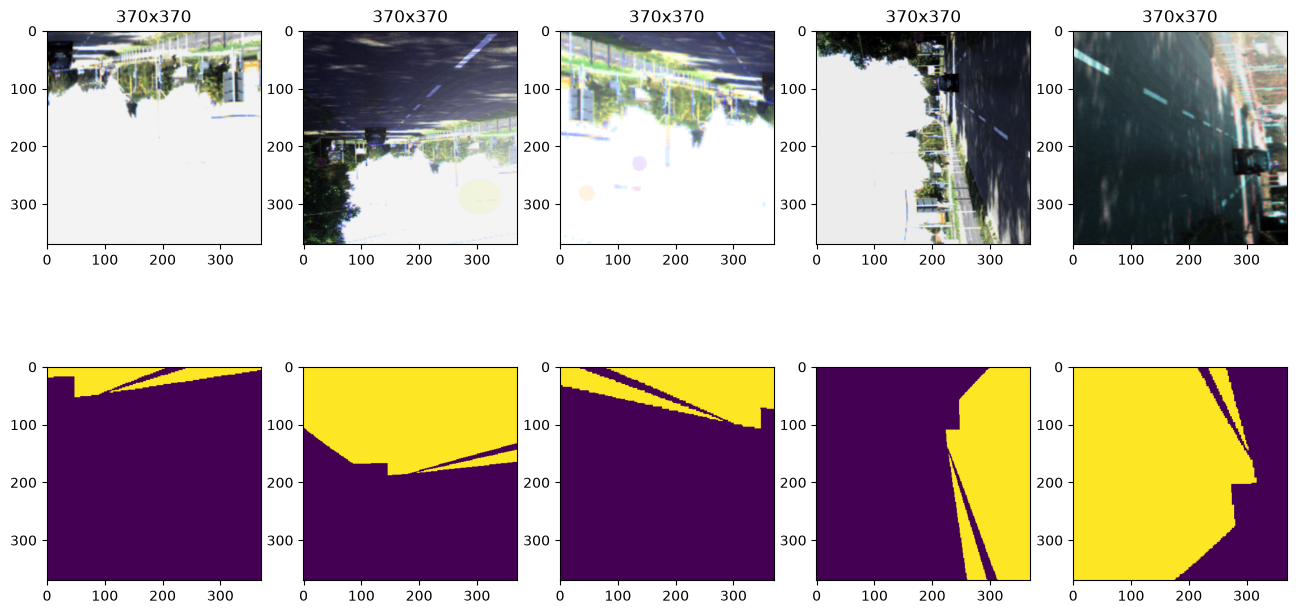

In [8]:
plt.figure(figsize=(16, 8))
for i in range(5):
    sample = train_dataset[239]
    image = sample['image']
    mask = sample['mask']

    plt.subplot(2, 5, 1+i)
    plt.imshow(image.permute(1, 2, 0))
    plt.title(f"{image.shape[1]}x{image.shape[2]}")
    plt.subplot(2, 5, 6+i)
    plt.imshow(mask.permute(1, 2, 0))

Workflow:
---
* Choose correct loss function, write training loop and code for testing. Feel free to use previous HW for inspiration. 
* Train any segmentation neural network from scratch (for example U-Net) and achieve >= 0.75 IoU on test set (40% points). See function to calculate the metric below.
* Use any pretrained model for image classification, convert it for segmentation by adding decoder (don't forget skip-connections) or usign dilated convolutions and achieve >= 0.87 IoU  on test set (60% points).

You're not allowed to do only one thing: train your network on test set.

----
Your final solution will consist of an ipython notebook with code (for final networks training + any experiments with data) and test metric calculation.

Feel free to ask in Telegram chat if something is not clear :3


In [9]:
print(f"Dataset length {len(train_dataset)}")

Dataset length 648


Dataset is small so actively use data augmentation: rotations, flip, color-change etc. to prevent overfitting.

Most likely you'll have to pad your images to 512x512 (it divides by 2^5=32, like U-Net wants). Use PadIfNeeded from Albumentations and central crop (see below) after prediction to calculate loss/metrics (you don't want to pay attention on padded values).

----
There is a hard data class imbalance in dataset, so the network output will be biased toward "zero" class. You can either tune the minimal probability threshold for the "road" class, or add class weights in optimized loss. You also can try to use softIoU or DICE loss.

Good luck!

In [10]:
def calc_iou(prediction, ground_truth):
    n_images = len(prediction)
    intersection, union = 0, 0
    for i in range(n_images):
        intersection += np.logical_and(prediction[i] > 0, ground_truth[i] > 0).astype(np.float32).sum() 
        union += np.logical_or(prediction[i] > 0, ground_truth[i] > 0).astype(np.float32).sum()
    return float(intersection) / union

In [11]:
def central_crop(images, size):
    current_size = images.size(2)
    border_len = (current_size - size) // 2
    images = images[:, :, border_len:current_size-border_len, border_len:current_size-border_len]
    return images

Call model


torch.Size([1, 1, 370, 370])

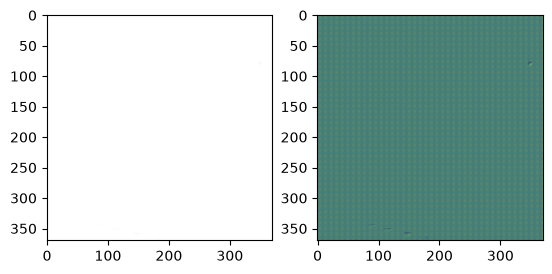

In [12]:
from math import ceil

class UNet(nn.Module):
    def __init__(self, input_size: int = 370, lowres_size: int = 32, img_channels: int = 3, init_channels: int = 64,
                 kernel_size: int = 3, resize_kernel_size: int = 2):
        super().__init__()
        self.device = torch.get_default_device()
        self.input_size = input_size

        _size = self.input_size
        _channels = None
        self.conv_seq = nn.ModuleList()
        pad_divisor = 1

        while True:
            self.conv_seq.append(nn.Sequential(
                nn.Conv2d(_channels or img_channels, 
                        (_channels := _channels << 1 if _channels else init_channels),
                        kernel_size,
                        padding='same',
                        padding_mode='reflect'),
                nn.ReLU(),
                nn.Conv2d(_channels, _channels, kernel_size, padding='same', padding_mode='reflect'),
                nn.ReLU()
            ))
            if _size <= lowres_size:
                break
            self.conv_seq.append(nn.MaxPool2d(resize_kernel_size))
            _size = ceil(_size / resize_kernel_size)
            pad_divisor *= resize_kernel_size
        self.upconv_seq = nn.ModuleList()
        while _size < self.input_size:
            self.upconv_seq.append(nn.ModuleDict({
                "upconv": nn.ConvTranspose2d(_channels, _channels >> 1, resize_kernel_size, stride=resize_kernel_size),
                "convs": nn.Sequential(
                    nn.Conv2d(_channels, _channels := _channels >> 1, kernel_size, padding='same', padding_mode='reflect'),
                    nn.ReLU(),
                    nn.Conv2d(_channels, _channels, kernel_size, padding='same', padding_mode='reflect'),
                    nn.ReLU()
                )
            }))
            _size *= resize_kernel_size
        self.segment = nn.Conv2d(_channels, 1, 1)

        self.autopad = albumentations.PadIfNeeded(
            None, None,
            pad_height_divisor=pad_divisor,
            pad_width_divisor=pad_divisor,
            border_mode=cv2.BORDER_REFLECT
        )
    
    def to(self, *args, **kwargs):
        if args and isinstance(args[0], torch.device):
            self.device = torch.device(args[0])
        elif 'device' in kwargs:
            self.device = torch.device(kwargs['device'])
        return super().to(*args, **kwargs)

    def forward(self, X: torch.Tensor):
        print("Call model")
        if X.shape[-1] != self.input_size or X.shape[-2] != self.input_size:
            raise ValueError(
                f"The model expects {self.input_size}x{self.input_size} images. "
                f"Input tensor has shape {X.shape}"
            )
        if X.dim() == 3:
            X = X.unsqueeze(0)
        residuals: list[torch.Tensor] = []
        is_maxpool: bool = False
        X = torch.tensor(self.autopad(images=X.permute(0, 2, 3, 1))["images"], device=self.device).permute(0, 3, 1, 2)
        for conv_transform in self.conv_seq:
            if is_maxpool:
                residuals.append(X)
            X = conv_transform(X)
            is_maxpool = not is_maxpool
        is_upconv: bool = True
        for upsample_layer, res in zip(self.upconv_seq, residuals[::-1]):
            upconv, convs = upsample_layer['upconv'], upsample_layer['convs']
            X = upconv(X)
            if is_upconv:
                X = torch.concat([res, X], dim=-3)
            X = convs(X)
        X = self.segment(X)
        return central_crop(X, self.input_size)

model = UNet().to(device)
model.train(False)
sample = train_dataset[239]
plt.subplot(1, 2, 1)
plt.imshow(sample['image'].permute(1, 2, 0))
output = model(sample['image'])
plt.subplot(1, 2, 2)
plt.imshow(output.detach().cpu()[0].permute(1, 2, 0))
output.shape

In [13]:
def compute_loss(predictions: torch.Tensor, gt: torch.Tensor):
    return F.binary_cross_entropy(predictions, gt).mean()

In [14]:
import numpy as np
import time

def eval_model(model: nn.Module, data_generator):
    iou = []
    model.train(False)
    with torch.no_grad():
        for batch in data_generator:
            logits = model(batch['image'])
            y_pred = logits.max(1)[1].data
            iou.append(calc_iou(y_pred, batch['mask']))
    return np.mean(iou)

            
def train_model(model: nn.Module, optimizer: nn.Module, train_data_generator):
    train_loss = []
    model.train(True)
    for batch in tqdm(train_data_generator):
        optimizer.zero_grad()

        # forward
        y_batch: torch.Tensor = batch['mask'].to(device)
        predictions = model(batch['image'])
        loss = compute_loss(predictions, y_batch)

        # backward
        loss.backward()
        optimizer.step()

        # metrics
        train_loss.append(loss.cpu().data.numpy())
    return np.mean(train_loss)


def train_loop(model: nn.Module, optimizer: nn.Module, train_data_generator, val_data_generator, num_epochs):
    """
    num_epochs - total amount of full passes over training data
    """
    losses: list[float] = []
    iou_percent: list[float] = []
    epoch_times: list[float] = []
    growing_axis: list[int] = []
    total_axis: list[int] = list(range(1, num_epochs+1))
    for epoch in range(num_epochs):
        start_time = time.time()
        
        train_loss = train_model(model, optimizer, train_data_generator)
        iou_value = eval_model(model, val_data_generator)
        epoch_time = time.time() - start_time

        losses.append(train_loss)
        iou_percent.append(iou_value * 100)
        epoch_times.append(epoch_time)
        growing_axis.append(epoch+1)

        clear_output(wait=True)
        _, axs = plt.subplots(1, 3, figsize=(15, 6))
        axs: list[Axes]
        for ax, title, ylabel, values in zip(
            axs,
            ["Epochs", "Training Loss", "Mean Validation IoU"],
            ["Epoch time", "Loss", "Average IoU, %"],
            [epoch_times, losses, iou_percent]
        ):
            ax.plot(growing_axis, values)
            ax.set_title(title)
            ax.set_xlabel("Epoch")
            ax.set_ylabel(ylabel)
            if title == "Epochs":
                ax.set_xticks(total_axis)
        plt.show()

In [15]:
model = UNet().to(device)
opt = torch.optim.Adam(model.parameters())

In [16]:
train_loop(model, opt, train_loader, test_loader, 5)

  0%|          | 0/324 [00:00<?, ?it/s]

Call model


/__w/pytorch/pytorch/aten/src/ATen/native/cuda/Loss.cu:89: operator(): block: [30,0,0], thread: [32,0,0] Assertion `input_val >= zero && input_val <= one` failed.
/__w/pytorch/pytorch/aten/src/ATen/native/cuda/Loss.cu:89: operator(): block: [30,0,0], thread: [33,0,0] Assertion `input_val >= zero && input_val <= one` failed.
/__w/pytorch/pytorch/aten/src/ATen/native/cuda/Loss.cu:89: operator(): block: [30,0,0], thread: [34,0,0] Assertion `input_val >= zero && input_val <= one` failed.
/__w/pytorch/pytorch/aten/src/ATen/native/cuda/Loss.cu:89: operator(): block: [30,0,0], thread: [35,0,0] Assertion `input_val >= zero && input_val <= one` failed.
/__w/pytorch/pytorch/aten/src/ATen/native/cuda/Loss.cu:89: operator(): block: [30,0,0], thread: [36,0,0] Assertion `input_val >= zero && input_val <= one` failed.
/__w/pytorch/pytorch/aten/src/ATen/native/cuda/Loss.cu:89: operator(): block: [30,0,0], thread: [37,0,0] Assertion `input_val >= zero && input_val <= one` failed.
/__w/pytorch/pytorch/a

AcceleratorError: CUDA error: device-side assert triggered
Search for `cudaErrorAssert' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
